# Siakam trade search + roster fact checks (2026-11-16)

Ligma Sugma (team 4). Build: win **PTS, AST, 3PM, STL, FT%**. Goal of this notebook:

1. **Fact-check** three claims about the roster with league data.
2. Decide whether **Pascal Siakam** needs to be moved to fix FT%, and if so, find **suitors**.

Simulation and value model: `analysis/trade_eval.py` (9-cat z-scores, aging curve, whole-league
Monte Carlo with every team's best legal lineup each day). See `docs/trade_2026-11-16_boozer_brown.md`.

In [14]:
import sys, itertools, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'analysis'))
import trade_eval as te
from fbb.db import read_sql

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
SEASON, ME = 2027, 4
TARGETS = ['PTS', 'AST', 'STL', 'FG3M', 'FT']
STREAMERS = ['Tre Jones', 'Kyle Kuzma', 'Moritz Wagner', 'Naji Marshall', 'Klay Thompson']   # your stated streaming slots
SIMS = 600

# chart style: reference palette (light surface)
BLUE, ORANGE, AQUA, RED = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
INK, INK2, MUTED, GRID, BASE, SURF, NEUTRAL = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb', '#f0efec'
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF, 'figure.dpi': 110,
    'axes.edgecolor': BASE, 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'text.color': INK, 'font.size': 10, 'legend.frameon': False, 'legend.labelcolor': INK2})

q = read_sql
print(q("SELECT max(as_of) rosters_as_of FROM core.rosters").iloc[0, 0],
      '| last game log:', q(f"SELECT max(game_date) FROM core.player_games WHERE season={SEASON}").iloc[0, 0])

2026-11-16 15:49:08.446062+00:00 | last game log: 2026-11-15


In [15]:
# models: value, aging, league simulator
m = te.Model(te.load_player_seasons(SEASON - 8, SEASON), SEASON, TARGETS)
L = te.League(m, SEASON, ME, {'Stephen Curry': 0.6})
R = L.rosters.copy()

def profile(r):
    pid = int(r.nba_player_id); t, age = m.talent(pid); cur = m.line(pid, SEASON)
    if t is None or cur is None: return None
    z = m.z(t); d = m.dynasty(pid, r.player_name, '')
    return {'team_id': r.get('team_id', 0), 'player': r.player_name, 'age': age,
            'pos': '/'.join(p for p in ['PG', 'SG', 'SF', 'PF', 'C'] if p in r.eligible_positions),
            'gp': int(cur.GP), 'ft_pct': cur.FTM / max(cur.FTA, 1e-9), 'fta': cur.FTA,
            **{c: z['z_' + c] for c in te.CATS}, 'z9': z['z9'], 'zT': z['zT'],
            'dyn9': sum(x['VAR9'] * 0.85 ** i for i, x in enumerate(d)),
            'dynT': sum(x['VART'] * 0.85 ** i for i, x in enumerate(d))}

V = pd.DataFrame([p for p in (profile(r) for _, r in R[R.nba_player_id.notna()].iterrows()) if p]).set_index('player')
FA = pd.DataFrame([p for p in (profile(r) for _, r in L.fa.iterrows()) if p and p['gp'] >= 5]).set_index('player')
FA['team_id'] = 0
ALL = pd.concat([V, FA])
mine = V[V.team_id == ME].sort_values('zT')
print(len(V), 'rostered players with games this season;', len(FA), 'free agents with 5+ games')

204 rostered players with games this season; 197 free agents with 5+ games


## 1. Fact checks

### Claim 1: "Ajay Mitchell is only on IR because he was out this weekend"

current slot / ESPN status: {'lineup_slot': 'IR', 'injury_status': 'ACTIVE', 'as_of': Timestamp('2026-11-16 15:49:08.446062+0000', tz='UTC')}


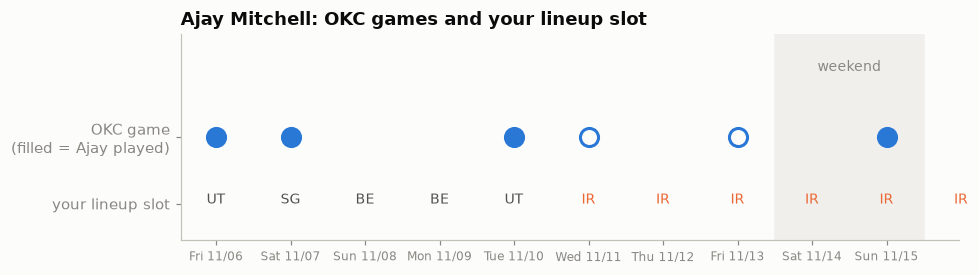

games Ajay played while in your IR slot: [{'game_date': datetime.date(2026, 11, 15), 'minutes': 27.0, 'pts': 14.0}]


In [16]:
aj = q(f'''SELECT d.scoring_period, d.lineup_slot, d.played, g.game_date, g.minutes, g.pts
          FROM core.player_days d LEFT JOIN core.player_games g
            ON g.espn_player_id = d.player_id AND g.season = d.season AND g.scoring_period = d.scoring_period
          WHERE d.season={SEASON} AND d.team_id={ME} AND d.player_name='Ajay Mitchell' AND d.scoring_period >= 18
          ORDER BY 1''')
okc = q(f'''SELECT DISTINCT game_date FROM core.player_games WHERE season={SEASON} AND team='OKC'
            AND game_date >= '2026-11-05' ORDER BY 1''')
played = set(q(f'''SELECT game_date FROM core.player_games WHERE season={SEASON} AND player_name='Ajay Mitchell' ''').game_date)
sp_date = q(f'''SELECT DISTINCT scoring_period, game_date FROM core.player_games WHERE season={SEASON}''').set_index('scoring_period').game_date
aj['date'] = aj.scoring_period.map(lambda s: pd.Timestamp('2026-10-20') + pd.Timedelta(days=s - 1))
status = q(f"SELECT lineup_slot, injury_status, as_of FROM core.rosters WHERE season={SEASON} AND player_name='Ajay Mitchell'")
print('current slot / ESPN status:', status.iloc[0].to_dict())

fig, ax = plt.subplots(figsize=(9, 2.6))
for _, g in okc.iterrows():
    d = pd.Timestamp(g.game_date); p = g.game_date in played
    ax.scatter(d, 1, s=140, color=BLUE if p else SURF, edgecolor=BLUE, linewidth=2, zorder=3)
for _, r in aj.iterrows():
    ax.text(r.date, 0.55, r.lineup_slot, ha='center', color=ORANGE if r.lineup_slot == 'IR' else INK2, fontsize=9)
for d in ['2026-11-14', '2026-11-15']:
    ax.axvspan(pd.Timestamp(d) - pd.Timedelta(hours=12), pd.Timestamp(d) + pd.Timedelta(hours=12), color=NEUTRAL, zorder=0)
ax.text(pd.Timestamp('2026-11-14 12:00'), 1.45, 'weekend', ha='center', color=MUTED, fontsize=9)
ax.set_ylim(0.3, 1.7); ax.set_yticks([1, 0.55], ['OKC game\n(filled = Ajay played)', 'your lineup slot']); ax.grid(False)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %m/%d')); ax.xaxis.set_major_locator(mdates.DayLocator())
plt.setp(ax.get_xticklabels(), rotation=0, fontsize=8)
ax.set_title('Ajay Mitchell: OKC games and your lineup slot')
plt.tight_layout(); plt.show()
ir_games = aj[(aj.lineup_slot == 'IR') & aj.played]
print('games Ajay played while in your IR slot:', ir_games[['game_date', 'minutes', 'pts']].to_dict('records'))

### Claim 2: "My bottom 5 (Jones, Kuzma, Wagner, Marshall, Thompson) are streaming slots that fill gaps"

bottom 5 by build value: ['Moritz Wagner', 'Kyle Kuzma', 'Myles Turner', 'Naji Marshall', 'Klay Thompson']
bottom 5 by 9-cat value: ['Moritz Wagner', 'Kyle Kuzma', 'Daniss Jenkins', 'Klay Thompson', 'Naji Marshall']


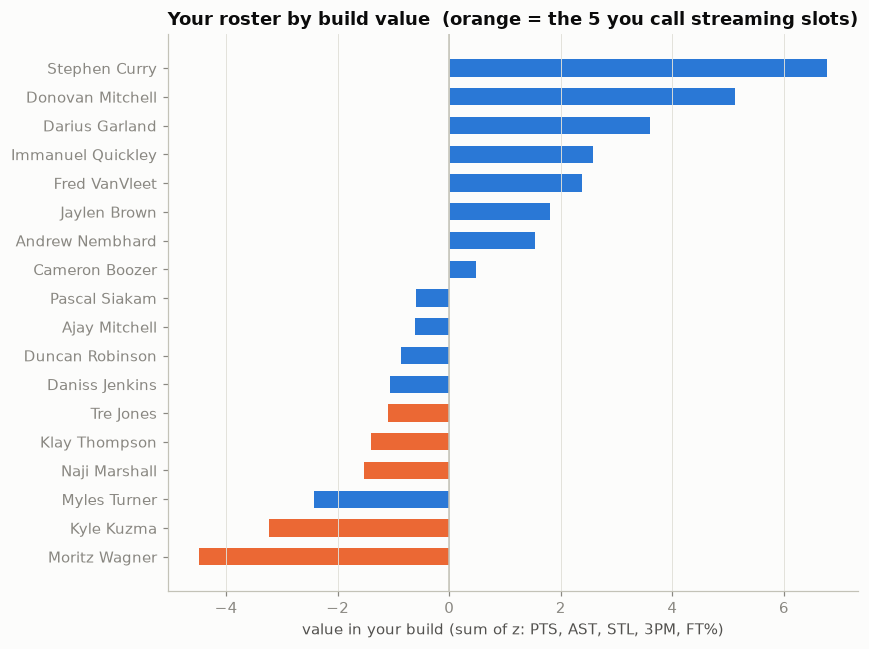

In [17]:
# (a) are they your bottom 5?  rank by value in YOUR build (target z) and in plain 9-cat z
rk = mine[['pos', 'zT', 'z9']].copy()
rk['rank_build'] = rk.zT.rank(); rk['rank_9cat'] = rk.z9.rank()
rk['named'] = rk.index.isin(STREAMERS)
print('bottom 5 by build value:', list(rk.nsmallest(5, 'zT').index))
print('bottom 5 by 9-cat value:', list(rk.nsmallest(5, 'z9').index))

fig, ax = plt.subplots(figsize=(8, 6))
order = rk.sort_values('zT')
ax.barh(order.index, order.zT, color=[ORANGE if n else BLUE for n in order.named], height=0.6)
ax.axvline(0, color=BASE, lw=1)
ax.set_xlabel('value in your build (sum of z: PTS, AST, STL, 3PM, FT%)')
ax.set_title('Your roster by build value  (orange = the 5 you call streaming slots)')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

18 players added; their games: 40 started, 28 played on your bench (41% wasted); guard-only adds: 6 of 18


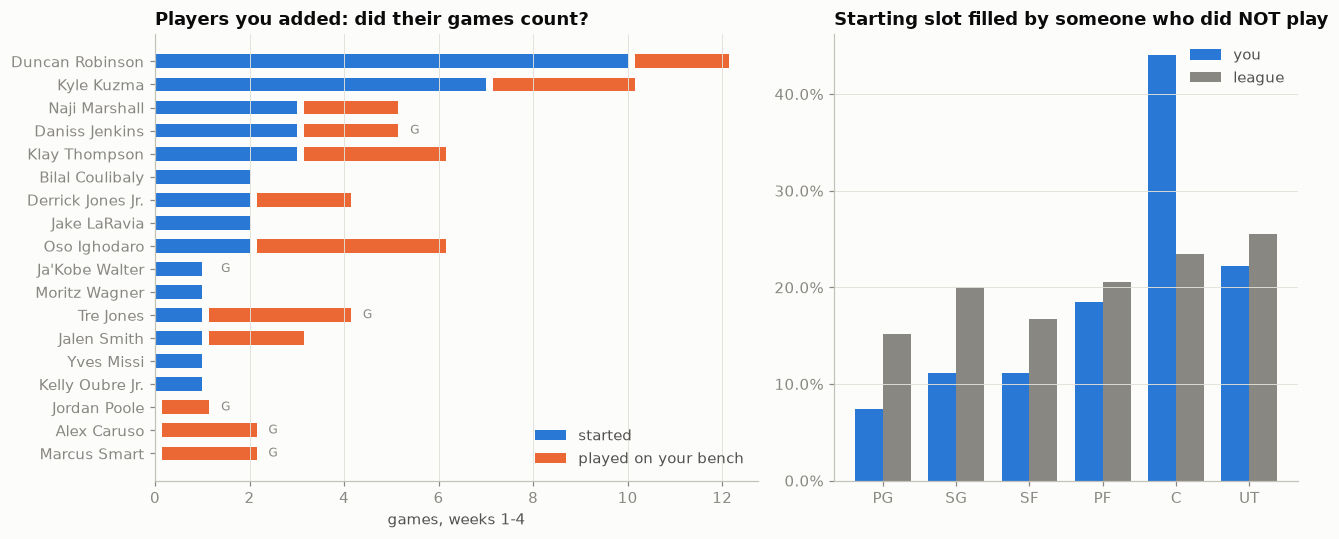

G = guard-only player
lineup_slot     PG     SG     SF     PF      C     UT
you          0.074  0.111  0.111  0.185  0.440  0.222
league       0.152  0.201  0.167  0.206  0.234  0.255


In [18]:
# (b) does streaming fill gaps?  every player you ADDED this season: games started vs games wasted on the bench
adds = q(f'''SELECT ti.player_id, ti.player_name, min(ti.happened_at) added
             FROM core.transaction_items ti JOIN core.transactions t USING (season, transaction_id)
             WHERE ti.season={SEASON} AND t.team_id={ME} AND ti.item_type='ADD' AND ti.status='EXECUTED'
             GROUP BY 1, 2''')
use = q(f'''SELECT player_id, count(*) FILTER (WHERE is_starter AND played) started,
                   count(*) FILTER (WHERE lineup_slot='BE' AND played) benched,
                   count(*) FILTER (WHERE lineup_slot='IR' AND played) on_ir
            FROM core.player_days WHERE season={SEASON} AND team_id={ME} AND matchup_period <= 4 GROUP BY 1''')
pos = q("SELECT player_id, eligible_positions FROM core.players")
s = adds.merge(use, on='player_id', how='left').merge(pos, on='player_id').fillna({'started': 0, 'benched': 0, 'on_ir': 0})
s['guard_only'] = s.eligible_positions.apply(lambda p: not any(x in p for x in ('SF', 'PF', 'C')))
s = s.sort_values('started')
tot = s[['started', 'benched']].sum()
print(f"{len(s)} players added; their games: {int(tot.started)} started, {int(tot.benched)} played on your bench "
      f"({tot.benched / tot.sum():.0%} wasted); guard-only adds: {s.guard_only.sum()} of {len(s)}")

# (c) where are the gaps?  starting-slot days where the starter didn't play while someone on the bench did
gaps = q(f'''WITH d AS (SELECT * FROM core.player_days WHERE season={SEASON} AND matchup_period BETWEEN 1 AND 4),
             b AS (SELECT team_id, scoring_period FROM d WHERE lineup_slot='BE' AND played GROUP BY 1, 2)
             SELECT d.team_id, d.lineup_slot, count(*) FILTER (WHERE NOT d.played) dnp,
                    count(*) FILTER (WHERE NOT d.played AND b.team_id IS NOT NULL) dnp_bench_played, count(*) slot_days
             FROM d LEFT JOIN b USING (team_id, scoring_period)
             WHERE d.lineup_slot NOT IN ('BE', 'IR') GROUP BY 1, 2''')
g_me = gaps[gaps.team_id == ME].set_index('lineup_slot')
g_lg = gaps.groupby('lineup_slot')[['dnp', 'slot_days']].sum()
rate = pd.DataFrame({'you': g_me.dnp / g_me.slot_days, 'league': g_lg.dnp / g_lg.slot_days}).loc[['PG', 'SG', 'SF', 'PF', 'C', 'UT']]

fig, axs = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axs[0]
ax.barh(s.player_name, s.started, color=BLUE, height=0.6, label='started')
ax.barh(s.player_name, s.benched, left=s.started + 0.15, color=ORANGE, height=0.6, label='played on your bench')
for i, (_, r) in enumerate(s.iterrows()):
    if r.guard_only: ax.text(r.started + r.benched + 0.4, i, 'G', va='center', color=MUTED, fontsize=8)
ax.set_xlabel('games, weeks 1-4'); ax.set_title('Players you added: did their games count?'); ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)
ax = axs[1]
x = np.arange(len(rate)); w = 0.38
ax.bar(x - w / 2, rate.you, w, color=BLUE, label='you'); ax.bar(x + w / 2, rate.league, w, color=MUTED, label='league')
ax.set_xticks(x, rate.index); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title('Starting slot filled by someone who did NOT play'); ax.legend(); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
print('G = guard-only player')
print(rate.round(3).T)

### Claim 3: "None of the centers fit my build"

your 10th-best player by build value: Moritz Wagner (target z -4.49)
C-eligible players at or above that bar: 42  (owners: {'other team': 33, 'free agent': 7, 'you': 2})


,owner,pos,age,ft_pct,PTS,AST,STL,FG3M,FT,zT,z9
player,,,,,,,,,,,
Nikola Jokic,other team,C,31,0.90,1.90,3.42,1.13,-0.10,0.52,6.87,10.46
Victor Wembanyama,other team,C,22,0.77,1.70,-0.11,-0.05,0.42,0.19,2.16,10.30
Joel Embiid,other team,C,32,0.89,1.29,0.18,-0.98,-0.68,1.46,1.26,1.31
Karl-Anthony Towns,other team,C,31,0.77,0.83,-0.27,-0.43,-0.05,0.60,0.67,3.21
Jaren Jackson Jr.,other team,PF/C,27,0.75,0.87,-0.70,0.16,0.22,-0.07,0.48,1.84
Bam Adebayo,other team,PF/C,29,0.76,0.56,-0.01,0.66,-0.43,-0.49,0.29,2.05
Alperen Sengun,other team,C,24,0.73,0.92,1.41,0.30,-1.02,-1.50,0.12,2.33
Anthony Davis,other team,PF/C,33,0.86,1.21,-0.40,0.23,-1.07,-0.08,-0.11,4.79
Naz Reid,other team,PF/C,27,0.65,-0.14,-0.61,-0.43,0.49,-0.30,-1.00,-0.52


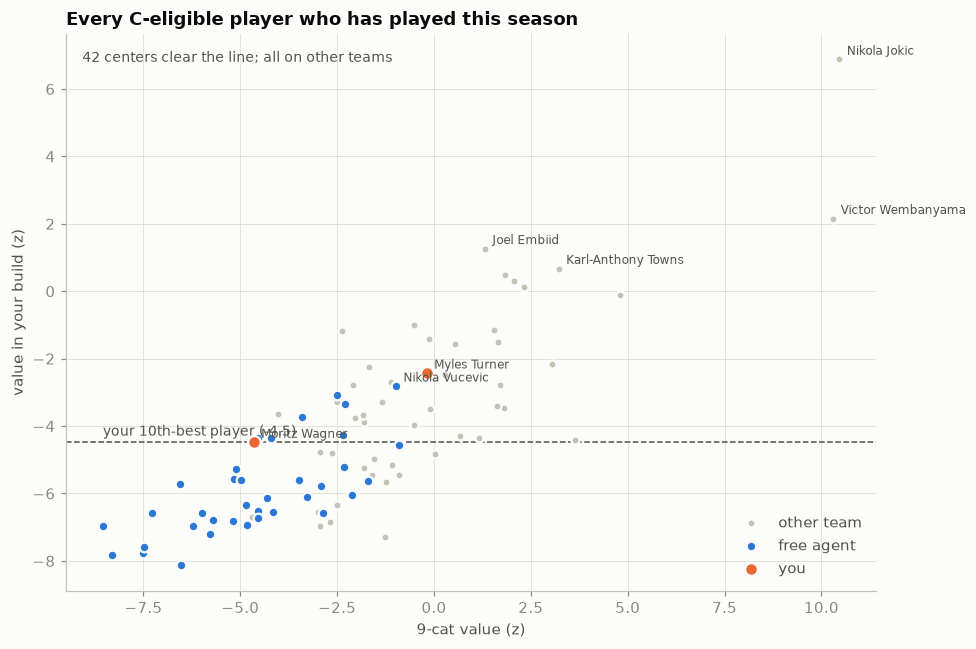

In [19]:
C = ALL[ALL.pos.str.contains('C')].copy()
C['owner'] = np.where(C.team_id == ME, 'you', np.where(C.team_id == 0, 'free agent', 'other team'))
starters = mine.sort_values('zT', ascending=False)          # your top-10 by build value
bar = starters.zT.min()
fits = C[C.zT >= bar].sort_values('zT', ascending=False)
print(f'your 10th-best player by build value: {starters.index[-1]} (target z {bar:.2f})')
print(f'C-eligible players at or above that bar: {len(fits)}  '
      f'(owners: {fits.owner.value_counts().to_dict()})')
display(fits[['owner', 'pos', 'age', 'ft_pct', 'PTS', 'AST', 'STL', 'FG3M', 'FT', 'zT', 'z9']].round(2).head(15))

fig, ax = plt.subplots(figsize=(9, 6))
for own, col, sz in (('other team', BASE, 28), ('free agent', BLUE, 40), ('you', ORANGE, 70)):
    d = C[C.owner == own]
    ax.scatter(d.z9, d.zT, s=sz, color=col, edgecolor=SURF, linewidth=1.5, label=own, zorder=3)
ax.axhline(bar, color=INK2, lw=1, ls='--'); ax.text(C.z9.min(), bar + 0.2, f'your 10th-best player ({bar:.1f})', color=INK2, fontsize=9)
for n, r in pd.concat([fits.head(4), C[C.owner == 'you'], C[C.owner == 'free agent'].nlargest(1, 'zT')]).iterrows():
    ax.annotate(n, (r.z9, r.zT), xytext=(5, 3), textcoords='offset points', fontsize=8, color=INK2)
ax.text(0.02, 0.97, f'{len(fits)} centers clear the line; all on other teams', transform=ax.transAxes,
        ha='left', va='top', color=INK2, fontsize=9)
ax.set_xlabel('9-cat value (z)'); ax.set_ylabel('value in your build (z)')
ax.set_title('Every C-eligible player who has played this season'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

## 2. Does Siakam need to move?

His FT% problem is volume: about 71% on 6.5 attempts a game. Below is his category profile, then what the
league simulation says he is worth to you (replace him with the best free agent).

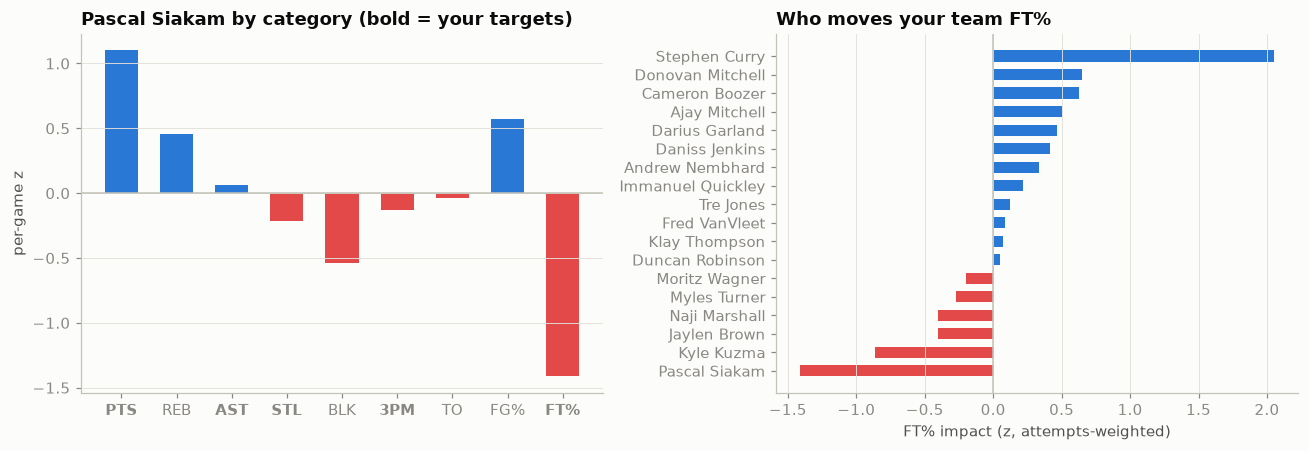

{'age': 32.0, 'gp': 13.0, 'ft_pct': 0.72, 'fta': 6.5, 'zT': -0.59, 'z9': -0.13, 'dyn9': 5.46}


In [20]:
cats = ['PTS', 'REB', 'AST', 'STL', 'BLK', 'FG3M', 'TOV', 'FG', 'FT']
lab = {'FG3M': '3PM', 'TOV': 'TO', 'FG': 'FG%', 'FT': 'FT%'}
sk = V.loc['Pascal Siakam', cats]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axs[0]
ax.bar([lab.get(c, c) for c in cats], sk, color=[BLUE if v >= 0 else RED for v in sk], width=0.6)
for i, c in enumerate(cats):
    if c in TARGETS: ax.get_xticklabels()[i].set_fontweight('bold')
ax.axhline(0, color=BASE, lw=1); ax.set_ylabel('per-game z'); ax.grid(axis='x', visible=False)
ax.set_title('Pascal Siakam by category (bold = your targets)')
ax = axs[1]
ft = mine.sort_values('FT')
ax.barh(ft.index, ft.FT, color=[RED if v < 0 else BLUE for v in ft.FT], height=0.6)
ax.axvline(0, color=BASE, lw=1); ax.set_xlabel('FT% impact (z, attempts-weighted)'); ax.grid(axis='y', visible=False)
ax.set_title('Who moves your team FT%')
plt.tight_layout(); plt.show()
print(V.loc['Pascal Siakam', ['age', 'gp', 'ft_pct', 'fta', 'zT', 'z9', 'dyn9']].round(2).to_dict())

In [21]:
# league simulation helpers (same engine as analysis/trade_eval.py)
BASE_IN, T0, RES0 = {}, {}, {}
for mode in ('talent', 'form'):
    BASE_IN[mode] = L.inputs(form_only=mode == 'form')
    T0[mode] = {t: L.sim_team(t, ps, SIMS)[0] for t, ps in BASE_IN[mode].items()}
    RES0[mode] = L.season_results(T0[mode], SIMS)
FA_POOL = {mode: L.free_agents(form_only=mode == 'form') for mode in ('talent', 'form')}

def player_in(name, mode, mine_targets):
    return L.player(L.rosters[L.rosters.player_name == name].iloc[0], mode == 'form', mine_targets)

def simulate(give, get, partner, mode):
    base = BASE_IN[mode]
    me = {k: v for k, v in base[ME].items() if k not in give}
    me.update({n: player_in(n, mode, True) for n in get})
    if partner:
        pt = {k: v for k, v in base[partner].items() if k not in get}
        pt.update({n: player_in(n, mode, False) for n in give})
    me = {k: v for k, v in me.items() if v}
    drop = None
    while len(me) > len(base[ME]):     # 1-for-2: drop your lowest-value non-incoming player
        drop = min((p for p in me.values() if p['name'] not in get), key=lambda p: p['val'])['name']; me.pop(drop)
    fas = iter(p for p in FA_POOL[mode] if p['name'] not in get)
    teams = [(ME, me)] + ([(partner, pt)] if partner else [])
    for t, ros in teams:
        while len(ros) < len(base[t]):
            p = next(fas); ros[p['name']] = p if t != ME else {**p, 'val': p['val_targets']}
    T = dict(T0[mode])
    for t, ros in teams: T[t] = L.sim_team(t, ros, SIMS)[0]
    res = L.season_results(T, SIMS)
    my, my0 = L.my_summary(res), L.my_summary(RES0[mode])
    out = {'drop': drop, **{f'd_{k}': my[k] - my0[k] for k in ['FT%', 'STL', 'FG3M', 'PTS', 'AST', 'exp_cats_won', 'P(playoffs)']}}
    if partner:
        out['their_d_playoffs'] = L.summary(res, partner)['P(playoffs)'] - L.summary(RES0[mode], partner)['P(playoffs)']
    return out

for mode in ('talent', 'form'):
    my0 = L.my_summary(RES0[mode])
    print(f"[{mode}] as is: P(win FT%) {my0['FT%']:.3f}, P(playoffs) {my0['P(playoffs)']:.3f}")
    r = simulate(['Pascal Siakam'], [], None, mode)      # Siakam out, best free agent in
    print(f"   Siakam -> best free agent: playoffs {r['d_P(playoffs)']:+.3f}, FT% {r['d_FT%']:+.3f}, PTS {r['d_PTS']:+.3f}")

[talent] as is: P(win FT%) 0.543, P(playoffs) 0.245
   Siakam -> best free agent: playoffs -0.082, FT% +0.011, PTS -0.103
[form] as is: P(win FT%) 0.553, P(playoffs) 0.428
   Siakam -> best free agent: playoffs -0.085, FT% +0.014, PTS -0.105


## 3. Siakam suitors

Constraints carried over from the Brown search: Siakam alone or plus one of your streaming slots;
returns age 30 or younger; STL and 3PM must not get worse; fair for the other manager.
**Fair** here = the other team doesn't lose more than 0.75 z of rest-of-season value or 1.0 of 5-year value,
and the simulation doesn't drop their playoff odds by more than 3 points.

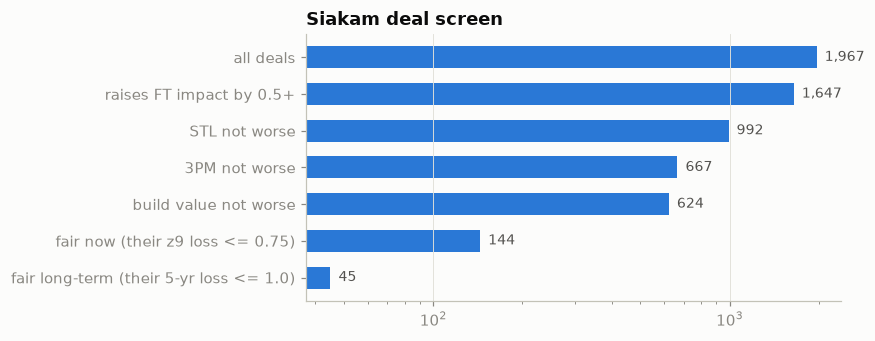

,team,deal,d_FT,d_STL,d_FG3M,d_PTS,d_zT,d_z9,d_dyn9
1848,Karaban Caravan,Pascal Siakam + Tre Jones -> Darius Acuff Jr.,1.80,0.09,2.61,1.09,6.77,0.47,-1.51
1426,Team Youngbois😎,Pascal Siakam -> Ja Morant,2.40,0.31,-0.07,-0.07,4.70,-0.09,-0.49
1843,Karaban Caravan,Pascal Siakam + Kyle Kuzma -> Mikel Brown Jr.,2.31,0.65,0.79,-1.14,3.16,-0.72,-4.32
1042,Jons of Soe Ingles,Pascal Siakam + Kyle Kuzma -> Jamal Shead,2.31,0.86,-0.07,-1.84,2.76,0.49,-5.16
215,Zebras,Pascal Siakam + Kyle Kuzma -> Egor Demin,2.26,0.43,1.15,-1.40,2.72,0.66,-3.36
1844,Karaban Caravan,Pascal Siakam + Moritz Wagner -> Mikel Brown...,1.64,1.01,1.21,-0.65,4.41,-0.32,-4.32
1648,Seattle SuperSonics,Pascal Siakam -> Ty Jerome,2.26,-0.05,0.49,-0.78,2.33,0.28,-0.58
74,TWIN FADE AWAY,Pascal Siakam + Kyle Kuzma -> Jared McCain,2.48,0.07,0.58,-1.37,1.29,-0.25,-5.24
275,Zebras,Pascal Siakam + Kyle Kuzma -> Bones Hyland,2.28,0.17,0.49,-1.64,1.35,0.39,-5.46
75,TWIN FADE AWAY,Pascal Siakam + Moritz Wagner -> Jared McCain,1.81,0.43,1.00,-0.89,2.54,0.15,-5.24


In [22]:
OUT = 'Pascal Siakam'
deals = []
for tid, g in V[V.team_id != ME].groupby('team_id'):
    elig = g[g.age <= 30]
    for get in [[p] for p in elig.index] + [list(c) for c in itertools.combinations(elig.index, 2)]:
        gives = [[OUT]] + ([[OUT, f] for f in STREAMERS if f in V.index] if len(get) == 1 else [])
        for give in gives:
            gi, ge = V.loc[give], V.loc[get]
            d = {c: ge[c].sum() - gi[c].sum() for c in ['FT', 'STL', 'FG3M', 'PTS', 'AST', 'zT', 'z9', 'dyn9']}
            deals.append({'team_id': tid, 'give_': give, 'get_': get, **{'d_' + k: v for k, v in d.items()}})
D = pd.DataFrame(deals)
steps = [('raises FT impact by 0.5+', D.d_FT >= 0.5), ('STL not worse', D.d_STL >= -0.1),
         ('3PM not worse', D.d_FG3M >= -0.1), ('build value not worse', D.d_zT >= 0),
         ('fair now (their z9 loss <= 0.75)', D.d_z9 <= 0.75), ('fair long-term (their 5-yr loss <= 1.0)', D.d_dyn9 <= 1.0)]
mask = pd.Series(True, index=D.index); funnel = [('all deals', len(D))]
for n, c in steps:
    mask &= c; funnel.append((n, int(mask.sum())))
F = D[mask].assign(score=lambda x: x.d_FT + x.d_zT / 3).sort_values('score', ascending=False)
short = F.groupby('team_id').head(3).head(20).copy()
short['team'] = short.team_id.map(L.names)
short['deal'] = short.give_.str.join(' + ') + '  ->  ' + short.get_.str.join(' + ')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh([f[0] for f in funnel][::-1], [f[1] for f in funnel][::-1], color=BLUE, height=0.6)
for i, f in enumerate(funnel[::-1]): ax.text(f[1], i, f'  {f[1]:,}', va='center', color=INK2, fontsize=9)
ax.set_xscale('log'); ax.set_title('Siakam deal screen'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
display(short[['team', 'deal', 'd_FT', 'd_STL', 'd_FG3M', 'd_PTS', 'd_zT', 'd_z9', 'd_dyn9']].round(2))

In [23]:
rows = []
for _, d in short.iterrows():
    row = {'team': d.team, 'deal': d.deal, 'd_dyn9': d.d_dyn9}
    for mode in ('talent', 'form'):
        r = simulate(d.give_, d.get_, d.team_id, mode)
        row.update({f'{k}_{mode}': v for k, v in r.items()})
    rows.append(row)
S = pd.DataFrame(rows)
S['my_playoffs'] = S[['d_P(playoffs)_talent', 'd_P(playoffs)_form']].mean(1)
S['their_playoffs'] = S[['their_d_playoffs_talent', 'their_d_playoffs_form']].mean(1)
S['fair'] = (S.their_d_playoffs_talent >= -0.03) & (S.their_d_playoffs_form >= -0.03)
S = S.sort_values('my_playoffs', ascending=False)
cols = ['team', 'deal', 'drop_talent', 'd_FT%_talent', 'd_FT%_form', 'd_STL_talent', 'd_FG3M_talent', 'd_PTS_talent',
        'd_P(playoffs)_talent', 'd_P(playoffs)_form', 'their_d_playoffs_talent', 'their_d_playoffs_form', 'd_dyn9', 'fair']
display(S[cols].round(3))

,team,deal,drop_talent,d_FT%_talent,d_FT%_form,d_STL_talent,d_FG3M_talent,d_PTS_talent,d_P(playoffs)_talent,d_P(playoffs)_form,their_d_playoffs_talent,their_d_playoffs_form,d_dyn9,fair
11,Zebras,Pascal Siakam + Kyle Kuzma -> Patrick Williams,None,0.020,0.032,-0.025,-0.050,-0.158,-0.130,-0.040,0.000,0.000,-5.463,True
6,Seattle SuperSonics,Pascal Siakam -> Ty Jerome,None,0.040,0.037,-0.032,0.004,-0.097,-0.093,-0.085,0.052,0.062,-0.575,True
0,Karaban Caravan,Pascal Siakam + Tre Jones -> Darius Acuff Jr.,None,0.022,0.024,-0.038,0.040,0.011,-0.073,-0.107,0.000,0.000,-1.512,True
8,Zebras,Pascal Siakam + Kyle Kuzma -> Bones Hyland,None,0.017,0.036,-0.029,-0.040,-0.156,-0.133,-0.072,0.002,0.000,-5.463,True
10,Team Youngbois😎,Pascal Siakam + Naji Marshall -> Jeremiah Fears,None,0.024,0.028,-0.025,-0.039,-0.108,-0.110,-0.118,0.078,0.060,-1.658,True
16,H-Tine Astromechs,Pascal Siakam + Tre Jones -> Collin Gillespie,None,0.010,0.024,-0.010,0.025,-0.147,-0.128,-0.115,0.265,0.222,-5.776,True
5,Karaban Caravan,Pascal Siakam + Moritz Wagner -> Mikel Brown...,None,0.016,0.025,-0.008,-0.029,-0.113,-0.083,-0.163,0.000,0.000,-4.319,True
1,Team Youngbois😎,Pascal Siakam -> Ja Morant,None,0.032,0.014,-0.025,-0.009,-0.078,-0.118,-0.137,0.073,0.060,-0.487,True
15,Jons of Soe Ingles,Pascal Siakam + Moritz Wagner -> Kingston Fl...,None,0.009,0.021,-0.019,-0.048,-0.141,-0.107,-0.163,0.178,0.068,-3.040,True
18,Jons of Soe Ingles,Pascal Siakam + Naji Marshall -> Jamal Shead,None,0.021,0.026,-0.048,-0.044,-0.192,-0.168,-0.115,0.173,0.065,-7.119,True


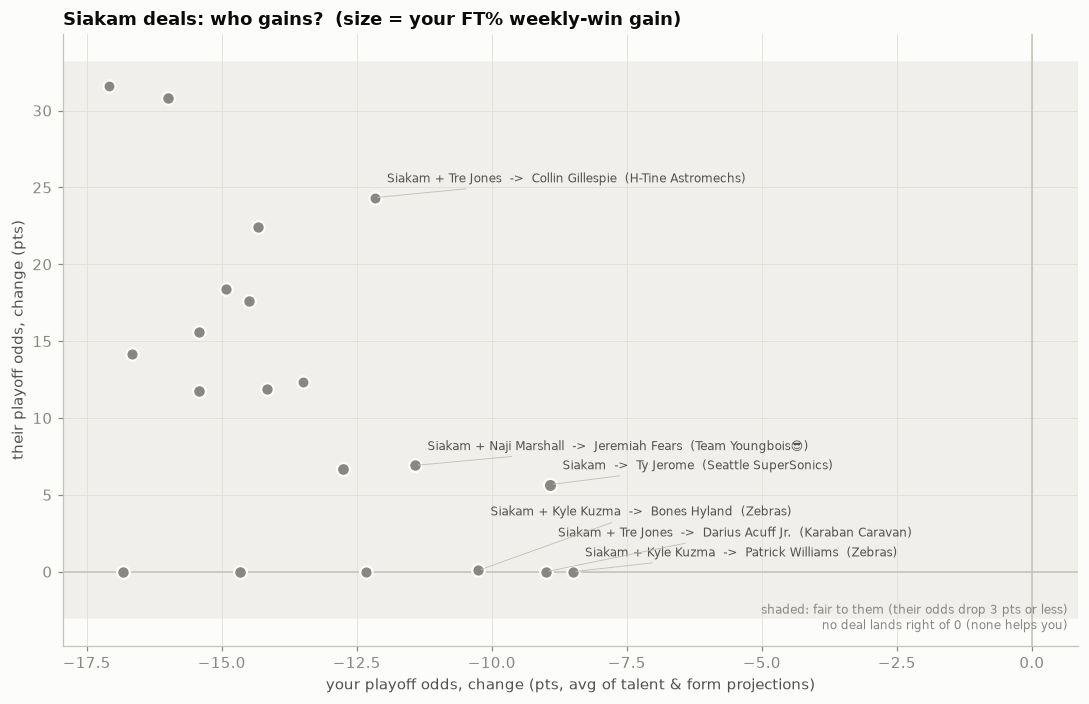

In [24]:
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.axhline(0, color=BASE, lw=1); ax.axvline(0, color=BASE, lw=1)
for _, r in S.iterrows():
    col = BLUE if r.my_playoffs > 0 and r.fair else (ORANGE if r.my_playoffs > 0 else MUTED)
    ax.scatter(r.my_playoffs * 100, r.their_playoffs * 100, s=60 + 400 * max(r['d_FT%_talent'], 0), color=col,
               edgecolor=SURF, linewidth=1.5, zorder=3)
ax.axhspan(-3, ax.get_ylim()[1], color=NEUTRAL, zorder=0)
# label the 6 deals that cost you least; stagger labels that share a y position
for k, (_, r) in enumerate(S.head(6).sort_values('their_playoffs').iterrows()):
    ax.annotate(f"{r.deal.replace('Pascal Siakam', 'Siakam')}  ({r.team})", (r.my_playoffs * 100, r.their_playoffs * 100),
                xytext=(8, 10 + 13 * (k if abs(r.their_playoffs) < 0.01 else 0)), textcoords='offset points',
                fontsize=8, color=INK2, arrowprops=dict(arrowstyle='-', color=BASE, lw=0.6))
ax.set_xlabel('your playoff odds, change (pts, avg of talent & form projections)')
ax.set_ylabel("their playoff odds, change (pts)")
ax.set_title('Siakam deals: who gains?  (size = your FT% weekly-win gain)')
ax.text(0.99, 0.02, 'shaded: fair to them (their odds drop 3 pts or less)\nno deal lands right of 0 (none helps you)',
        transform=ax.transAxes, ha='right', va='bottom', color=MUTED, fontsize=8)
plt.tight_layout(); plt.show()

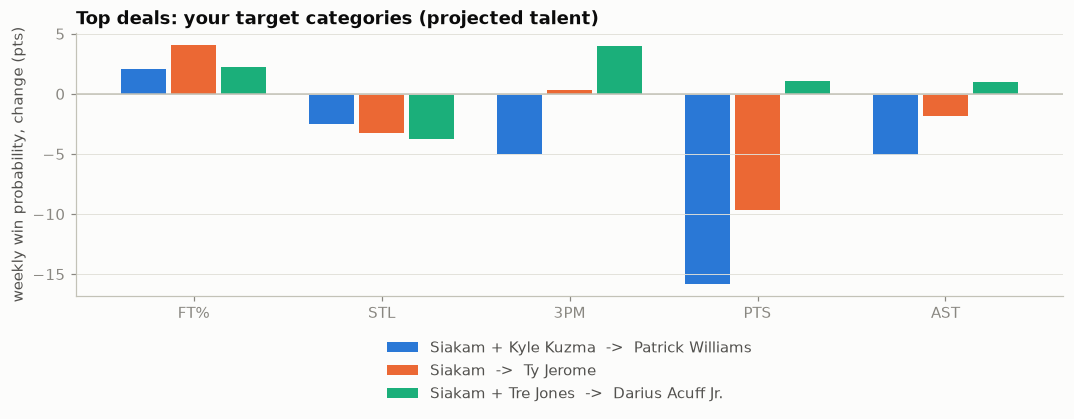

In [25]:
top = S[(S.my_playoffs > 0) & S.fair].head(3)
if top.empty: top = S.head(3)
cat_cols = ['d_FT%_talent', 'd_STL_talent', 'd_FG3M_talent', 'd_PTS_talent', 'd_AST_talent']
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(cat_cols)); w = 0.8 / len(top)
for i, (_, r) in enumerate(top.iterrows()):
    ax.bar(x + i * w - 0.4 + w / 2, r[cat_cols].values * 100, w * 0.9, color=[BLUE, ORANGE, AQUA][i],
           label=r.deal.replace('Pascal Siakam', 'Siakam'))
ax.axhline(0, color=BASE, lw=1); ax.set_xticks(x, ['FT%', 'STL', '3PM', 'PTS', 'AST'])
ax.set_ylabel('weekly win probability, change (pts)'); ax.grid(axis='x', visible=False)
ax.set_title('Top deals: your target categories (projected talent)'); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=1)
plt.tight_layout(); plt.show()

## 4. Conclusions (from the run on 2026-11-16; 600 seasons per scenario)

**Fact checks**

| Claim | Verdict | Evidence |
|---|---|---|
| Ajay is on IR because he was out this weekend | **Not supported** | He missed Wed 11/11 and Fri 11/13. OKC had no game Saturday, and he **played Sunday 11/15** (27 min, 14 pts) from your IR slot, so those stats didn't count. ESPN lists him ACTIVE. Keeping him on IR while you decide who to drop is reasonable; the stated reason isn't. |
| Jones, Kuzma, Wagner, Marshall, Klay are your bottom 5 and your streaming slots | **Mostly true** | By build value the bottom 5 are Wagner, Kuzma, **Turner**, Marshall, Klay. Tre Jones is 13th of 18; Jenkins and Robinson rank below him. Turner is your C, so the slot logic holds. |
| Streaming fills gaps through the week | **Partly** | Your guard and wing slots go unused less often than the league average (PG 7% vs 15%). But **41%** of the games played by players you added came on your bench, and the **C slot was filled by a non-playing player 44% of the time**, almost double the league's 23%. |
| None of the centers fit my build | **True for anyone you can get** | Only 8 C-eligible players reach your 10th-best player's build value (Jokic, Wembanyama, Embiid, Towns, JJJ, Adebayo, Sengun, Davis), all on other teams. No free-agent center comes close. The cost of that choice is the empty C slot above. |

**Siakam: keep him.**

- Replacing him with the best free agent costs **about 8 points of playoff odds** in both projections, mostly through PTS (about −10 points of weekly win rate).
- 9,000+ deals were screened and 20 simulated. **Every one lowers your playoff odds, by 4 to 21 points.** FT% gains top out at +4 points of weekly win rate, much less than the PTS you lose.
- The other side gains up to **+31 points** of playoff odds, so contenders value Siakam far more than his rating in your build suggests. If you ever do move him, sell to a contender and ask for a lot.
- FT% is a percentage category, so one player moves it only a little. Your biggest FT% swings are **Curry's return** (+2.05, the largest on the roster), **Kuzma off the roster** (−0.87), and **Brown's FT% recovering** toward his 79% (he's at 70% now).